# Практика · ML Handbook гл. 36 (DL optimization)

Источник: [dl-optimization](https://mlhandbook-production.up.railway.app/parts/deep-learning/dl-optimization.html)

Теория: [d.4.36 … .md](../d.4.36%20Оптимизация%20и%20обучение%20в%20DL/d.4.36%20Оптимизация%20и%20обучение%20в%20DL.md) · [README.md](./README.md)

**Handbook-код — в этом файле**. Эталон: [handbook_gl36_практика_решения.ipynb](./handbook_gl36_практика_решения.ipynb) **после** попытки. Deep-ML: [deep_ml/](./deep_ml/README.md).

| ☐ | Блок |
|---|------|
| ☐ | §36.5 He init |
| ☐ | §36.3 BatchNorm |
| ☐ | §36.6 BN ускоряет loss |
| ☐ | сходимость Adam vs SGD |


# §36.5 · Наглядно: почему инициализация критична


Чеклист: [handbook_gl36_практика.ipynb](./handbook_gl36_практика.ipynb)

In [8]:
import numpy as np

np.random.seed(0)
n = 1000
x = np.random.randn(n)


def probe(scale, name, layers=10):
    a = x.copy()
    for _ in range(layers):
        W = np.random.randn(n, n) * scale
        a = np.maximum(0, W @ a)
    print(f"{name:28s}: std = {a.std():.2e}")


probe(0.1, "слишком большой (0.1)")
probe(0.01, "слишком малый (0.01)")
probe(np.sqrt(2 / n), "He √(2/n)")
# ожидание на сайте: ~2.27e+03, ~2.24e-07, ~8.18e-01

слишком большой (0.1)       : std = 2.27e+03
слишком малый (0.01)        : std = 2.24e-07
He √(2/n)                   : std = 8.18e-01


---


# §36.3 · BatchNorm1d

`Linear → BatchNorm → ReLU`, батч 32×10 → выход 32×20.

In [9]:
import torch
from torch import nn

layer = nn.Sequential(nn.Linear(10, 20), nn.BatchNorm1d(20), nn.ReLU())
x = torch.randn(32, 10)
y = layer(x)
assert tuple(y.shape) == (32, 20)
print("форма выхода:", tuple(y.shape))

форма выхода: (32, 20)


---


# §36.6 · BatchNorm стабилизирует обучение

Две **одинаковые** сети: с `BatchNorm1d` после linear и без. Синтетика `X, y` + Adam, 20–50 эпох. Подсказка: на 2+ скрытых слоях BN обычно **ниже loss** уже к ~10-й эпохе и в конце.

Сначала допиши `mlp` и `train_curve`, потом раскомментируй проверку внизу ячейки.

In [10]:
import torch
from torch import nn


def mlp(with_bn: bool) -> nn.Module: ...


def train_curve(model, epochs: int = 40) -> list[float]: ...


# После реализации — раскомментируй и запусти ещё раз:
# loss_bn = train_curve(mlp(True))
# loss_plain = train_curve(mlp(False))
# print("final BN / plain:", loss_bn[-1], loss_plain[-1])
# print("epoch 10 BN / plain:", loss_bn[9], loss_plain[9])
# assert loss_bn[-1] < loss_plain[-1]
# assert loss_bn[9] < loss_plain[9]

---


# Два уровня (ментор) · Adam NumPy vs torch.optim

После [#49](./deep_ml/49_adam_optimizer%20—%20medium/). Одна задача (например MSE на 2D квадратичной loss): сравни траектории **SGD**, **Adam** (`torch.optim`) и своего NumPy-Adam.

Text(0.5, 0, 'step')

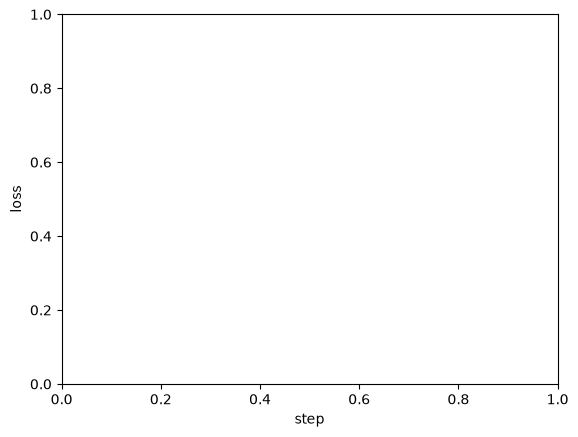

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import torch


def loss_and_grad(w): ...


# TODO: numpy adam (#49) + torch SGD/Adam на тех же стартовых w
plt.ylabel("loss")
plt.xlabel("step")